In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
!pip install librosa


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 31.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [librosa]


In [9]:
filename = '/Users/sehajluthra/Documents/sehaj_dataset/audio/clean/LA_E_1003257.wav'
import IPython.display as ipd
import librosa 
import librosa.display

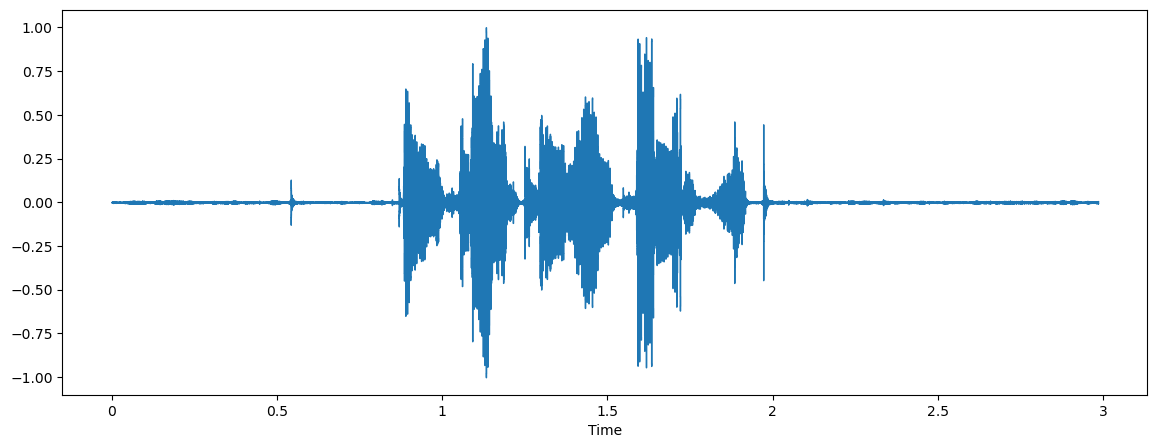

In [11]:
plt.figure(figsize=(14,5))
data , sample_rate = librosa.load(filename)
ipd.Audio(filename)
librosa.display.waveshow(data , sr=sample_rate)


In [12]:
sample_rate

22050

In [ ]:
data ## Normalized thats y not using scipy rn

array([0.0024383 , 0.00273247, 0.00228032, ..., 0.00600352, 0.00661356,
       0.00326728], shape=(65814,), dtype=float32)

In [38]:
df=pd.read_csv('/Users/sehajluthra/Documents/sehaj_dataset/labels.csv')

df.shape

(15000, 10)

In [39]:
df.head(10)

,file,label,label_id,split,speaker_id,language,fake_type,condition,source,orig_label
0,audio/clean/LA_E_1002903.wav,real,1,train,LA_0028,english,NaN,clean,asvspoof2019,bonafide
1,audio/gsm/LA_E_1002903.wav,real,1,train,LA_0028,english,NaN,gsm,asvspoof2019,bonafide
2,audio/g711u/LA_E_1002903.wav,real,1,train,LA_0028,english,NaN,g711u,asvspoof2019,bonafide
3,audio/clean/LA_E_1003128.wav,real,1,train,LA_0027,english,NaN,clean,asvspoof2019,bonafide
4,audio/gsm/LA_E_1003128.wav,real,1,train,LA_0027,english,NaN,gsm,asvspoof2019,bonafide
5,audio/g711u/LA_E_1003128.wav,real,1,train,LA_0027,english,NaN,g711u,asvspoof2019,bonafide
6,audio/clean/LA_E_1003257.wav,fake,0,train,LA_0043,english,A19,clean,asvspoof2019,spoof
7,audio/gsm/LA_E_1003257.wav,fake,0,train,LA_0043,english,A19,gsm,asvspoof2019,spoof
8,audio/g711u/LA_E_1003257.wav,fake,0,train,LA_0043,english,A19,g711u,asvspoof2019,spoof
9,audio/clean/LA_E_1008103.wav,fake,0,train,LA_0011,english,A07,clean,asvspoof2019,spoof


In [40]:
df.drop(columns=['language','speaker_id','fake_type','source','condition','orig_label'],inplace=True)

In [41]:
df.head(10)

,file,label,label_id,split
0,audio/clean/LA_E_1002903.wav,real,1,train
1,audio/gsm/LA_E_1002903.wav,real,1,train
2,audio/g711u/LA_E_1002903.wav,real,1,train
3,audio/clean/LA_E_1003128.wav,real,1,train
4,audio/gsm/LA_E_1003128.wav,real,1,train
5,audio/g711u/LA_E_1003128.wav,real,1,train
6,audio/clean/LA_E_1003257.wav,fake,0,train
7,audio/gsm/LA_E_1003257.wav,fake,0,train
8,audio/g711u/LA_E_1003257.wav,fake,0,train
9,audio/clean/LA_E_1008103.wav,fake,0,train


In [42]:
df.drop('label_id',axis=1,inplace=True)

In [43]:
df.head(10)

,file,label,split
0,audio/clean/LA_E_1002903.wav,real,train
1,audio/gsm/LA_E_1002903.wav,real,train
2,audio/g711u/LA_E_1002903.wav,real,train
3,audio/clean/LA_E_1003128.wav,real,train
4,audio/gsm/LA_E_1003128.wav,real,train
5,audio/g711u/LA_E_1003128.wav,real,train
6,audio/clean/LA_E_1003257.wav,fake,train
7,audio/gsm/LA_E_1003257.wav,fake,train
8,audio/g711u/LA_E_1003257.wav,fake,train
9,audio/clean/LA_E_1008103.wav,fake,train


In [44]:
train = df[df.split == 'train']
val   = df[df.split == 'val']
test  = df[df.split == 'test']

In [46]:
print(len(train), len(val), len(test))
print(train['label'].value_counts())

10575 2364 2061
label
fake    5487
real    5088
Name: count, dtype: int64


In [47]:
mfccs=librosa.feature.mfcc(y=data , sr = sample_rate , n_mfcc=40)
print(mfccs.shape)

(40, 129)


In [48]:
mfccs

array([[-539.21295  , -537.9985   , -541.27045  , ..., -492.80627  ,
        -499.2555   , -497.93192  ],
       [  64.11449  ,   64.96427  ,   61.72309  , ...,   96.828156 ,
          92.18883  ,   94.3889   ],
       [  41.471596 ,   42.022545 ,   42.723404 , ...,   27.59707  ,
          30.04739  ,   32.849167 ],
       ...,
       [  -4.1812906,   -3.5046294,   -4.566633 , ...,  -10.883818 ,
          -5.1959515,   -2.7325206],
       [  -3.7119775,   -5.806825 ,   -9.423462 , ...,   -5.397106 ,
          -3.1128485,   -1.5969937],
       [  -1.6839886,   -6.008422 ,  -12.626622 , ...,   -1.6965891,
          -2.3916469,   -2.8025174]], shape=(40, 129), dtype=float32)

In [49]:
def features_extractor(file):
    audio , sample_rate = librosa.load(file_name , res_type = 'kaiser_fast')
    mfccs_features = librosa.feature.mfcc(y=audio, sr=sample_rate, n_mfcc=40)
    mfccs_scaled_features = np.mean(mfccs_features.T,axis=0)
    
    return mfccs_scaled_features

In [57]:
import os
from tqdm import tqdm

base = '/Users/sehajluthra/Documents/sehaj_dataset'

# df has: file, label, split
df['path'] = df['file'].apply(lambda f: os.path.join(base, f))

# if label is text (real/fake), convert it to 0/1; if it's already numbers, this is skipped
if df['label'].dtype == object:
    df['label'] = df['label'].map({'fake': 0, 'real': 1})

# check that every file is found
print("missing:", (~df['path'].apply(os.path.exists)).sum())   # should be 0

def features_extractor(path, sr=16000, n_mfcc=40, max_frames=128):
    y, _ = librosa.load(path, sr=sr)
    mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=n_mfcc)
    if mfcc.shape[1] < max_frames:
        mfcc = np.pad(mfcc, ((0, 0), (0, max_frames - mfcc.shape[1])))
    else:
        mfcc = mfcc[:, :max_frames]
    return mfcc

extracted_features = []
for _, row in tqdm(df.iterrows(), total=len(df)):
    data = features_extractor(row['path'])
    extracted_features.append([data, row['label'], row['split']])

ext_df = pd.DataFrame(extracted_features, columns=['feature', 'label', 'split'])

train_df = ext_df[ext_df.split == 'train']
val_df   = ext_df[ext_df.split == 'val']
test_df  = ext_df[ext_df.split == 'test']

X_train = np.array(train_df['feature'].tolist()); y_train = train_df['label'].values
X_val   = np.array(val_df['feature'].tolist());   y_val   = val_df['label'].values
X_test  = np.array(test_df['feature'].tolist());  y_test  = test_df['label'].values

print(X_train.shape, X_val.shape, X_test.shape)
# expected: (10575, 40, 128) (2364, 40, 128) (2061, 40, 128)

missing: 0


100%|██████████| 15000/15000 [00:36<00:00, 409.13it/s]

(10575, 40, 128) (2364, 40, 128) (2061, 40, 128)


In [59]:
extracted_features_df = pd.DataFrame(extracted_features, columns=['feature', 'label', 'split'])
extracted_features_df.head(10)

,feature,label,split
0,"[[-478.3331, -451.29514, -441.92517, -441.4336...",1,train
1,"[[-483.61035, -452.79404, -447.57187, -448.481...",1,train
2,"[[-476.55948, -449.2828, -440.80658, -440.6280...",1,train
3,"[[-507.45386, -495.4309, -496.2657, -505.2538,...",1,train
4,"[[-505.14734, -493.647, -494.61285, -503.33542...",1,train
5,"[[-506.3026, -493.77588, -495.03976, -503.0567...",1,train
6,"[[-531.8541, -528.07733, -530.08606, -527.4475...",0,train
7,"[[-539.23474, -531.0209, -529.96436, -527.7671...",0,train
8,"[[-530.3624, -525.36707, -526.31335, -524.3267...",0,train
9,"[[-414.69724, -188.62354, -101.03745, -68.8447...",0,train


In [61]:
### Split the dataset into independent and dependent dataset
x=np.array(extracted_features_df['feature'].tolist())
y=np.array(extracted_features_df['label'].tolist())

In [62]:
x.shape

(15000, 40, 128)

In [63]:
y

array([1, 1, 1, ..., 1, 1, 1], shape=(15000,))

In [64]:
s = extracted_features_df['split'].values

X_train, y_train = x[s == 'train'], y[s == 'train']
X_val,   y_val   = x[s == 'val'],   y[s == 'val']
X_test,  y_test  = x[s == 'test'],  y[s == 'test']

print(X_train.shape, X_val.shape, X_test.shape)

(10575, 40, 128) (2364, 40, 128) (2061, 40, 128)


In [66]:
print(np.isnan(x).sum(), np.isinf(x).sum())    # both should be 0
print(np.unique(y, return_counts=True))        # (array([0, 1]), array([7500, 7500]))
print(df['file'].duplicated().sum())           # should be 0

0 0
(array([0, 1]), array([7500, 7500]))
0


In [67]:
np.savez('features.npz', X_train=X_train, y_train=y_train,
         X_val=X_val, y_val=y_val, X_test=X_test, y_test=y_test)

In [68]:
cond = df['file'].str.split('/').str[1].values   # same row order as x and y
cond_test = cond[s == 'test']

In [69]:
from sklearn.model_selection import train_test_split

X_train, X_temp, y_train, y_temp = train_test_split(x, y, test_size=0.3, random_state=42, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

In [72]:
!pip install tensorflow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 223.8/223.8 MB 12.3 MB/s  0:00:18m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.3/12.3 MB 17.7 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.8/2.8 MB 18.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 565.5/565.5 kB 13.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 18.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.8/25.8 MB 18.6 MB/s  0:00:01 eta 0:00:01
  Attempting uninstall: protobuf━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━  2/16 [flatbuffers]
    Found existing installation: protobuf 5.29.3━━━━━━━━━━━━━━  2/16 [flatbuffers]
    Uninstalling protobuf-5.29.3:━━━━━━━━━━━━━━━━━━━━━━━━━━━━━  2/16 [flatbuffers]
      Successfully uninstalled protobuf-5.29.3━━━━━━━━━━━━━━━━  2/16 [flatbuffers]
  Attempting uninstall: h5py━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━  2/16 [flatbuffers]
    Found existing installation: h5py 3.15.1━━━━━━━━━━━━━━━━━━  2/16 [flatbuffers]
    U

In [1]:
import tensorflow as tf
print(tf.__version__)

2.21.0


In [7]:
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Activation, Flatten, BatchNormalization, Input
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping
from sklearn import metrics
from datetime import datetime

# load the saved, correctly split arrays
d = np.load('features.npz')
X_train, y_train = d['X_train'], d['y_train']
X_val,   y_val   = d['X_val'],   d['y_val']
X_test,  y_test  = d['X_test'],  d['y_test']

# normalize per coefficient, using train statistics only
mean = X_train.mean(axis=(0, 2), keepdims=True)
std  = X_train.std(axis=(0, 2), keepdims=True) + 1e-8
X_train = (X_train - mean) / std
X_val   = (X_val - mean) / std
X_test  = (X_test - mean) / std

print(X_train.shape, X_val.shape, X_test.shape)
# expected: (10575, 40, 128) (2364, 40, 128) (2061, 40, 128)

(10575, 40, 128) (2364, 40, 128) (2061, 40, 128)


In [8]:
model = Sequential()

model.add(Input(shape=(40, 128)))
model.add(Flatten())

model.add(Dense(256))
model.add(Activation('relu'))
model.add(BatchNormalization())
model.add(Dropout(0.5))

model.add(Dense(128))
model.add(Activation('relu'))
model.add(Dropout(0.4))

model.add(Dense(64))
model.add(Activation('relu'))
model.add(Dropout(0.3))

model.add(Dense(1))
model.add(Activation('sigmoid'))   # output near 0 = fake, near 1 = real

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 5120)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     1,310,976 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 1)              │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,353,217 (5.16 MB)

 Trainable params: 1,352,705 (5.16 MB)

 Non-trainable params: 512 (2.00 KB)

In [9]:
model.compile(loss='binary_crossentropy',
              optimizer='adam',
              metrics=['accuracy', tf.keras.metrics.AUC(name='auc')])

In [10]:
os.makedirs('saved_models', exist_ok=True)

checkpointer = ModelCheckpoint(filepath='saved_models/audio_classification.keras',
                               monitor='val_loss', verbose=1, save_best_only=True)
early_stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

start = datetime.now()

history = model.fit(X_train, y_train,
                    batch_size=64, epochs=100,
                    validation_data=(X_val, y_val),
                    callbacks=[checkpointer, early_stop], verbose=1)

print("Training completed in time:", datetime.now() - start)

Epoch 1/100
157/166 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8682 - auc: 0.9313 - loss: 0.3209
Epoch 1: val_loss improved from None to 0.24982, saving model to saved_models/audio_classification.keras

Epoch 1: finished saving model to saved_models/audio_classification.keras
166/166 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8699 - auc: 0.9330 - loss: 0.3169 - val_accuracy: 0.8997 - val_auc: 0.9598 - val_loss: 0.2498
Epoch 2/100
155/166 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9308 - auc: 0.9802 - loss: 0.1704
Epoch 2: val_loss did not improve from 0.24982
166/166 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9301 - auc: 0.9799 - loss: 0.1720 - val_accuracy: 0.8858 - val_auc: 0.9546 - val_loss: 0.2621
Epoch 3/100
162/166 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9520 - auc: 0.9886 - loss: 0.1282
Epoch 3: val_loss did not improve from 0.24982
166/166 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9520 - auc: 0.9886 - loss: 0.1279 - val_accuracy: 0.9019 - val_auc: 0.

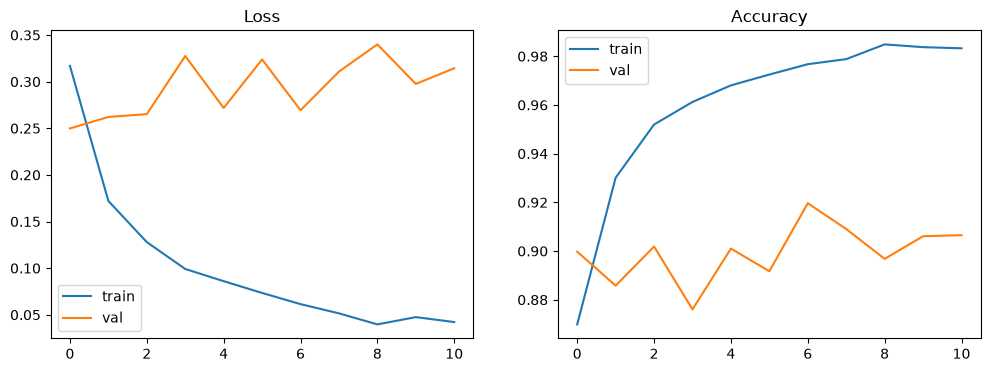

In [11]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history.history['loss'], label='train'); ax[0].plot(history.history['val_loss'], label='val')
ax[0].set_title('Loss'); ax[0].legend()
ax[1].plot(history.history['accuracy'], label='train'); ax[1].plot(history.history['val_accuracy'], label='val')
ax[1].set_title('Accuracy'); ax[1].legend()
plt.show()

In [ ]:
import pandas as pd
labels = pd.read_csv('/Users/sehajluthra/Documents/sehaj_dataset/labels.csv')
cond_test = labels.loc[labels.split == 'test', 'file'].str.split('/').str[1].values
print(len(cond_test))   

2061


In [14]:
print("test accuracy:", model.evaluate(X_test, y_test, verbose=0)[1])

y_prob = model.predict(X_test).ravel()
y_pred = (y_prob > 0.5).astype(int)

print(metrics.classification_report(y_test, y_pred, target_names=['fake', 'real']))
print(metrics.confusion_matrix(y_test, y_pred))
print("AUC:", metrics.roc_auc_score(y_test, y_prob))

for c in ['clean', 'gsm', 'g711u']:
    m = cond_test == c
    print(c, (y_pred[m] == y_test[m]).mean())

test accuracy: 0.9252789616584778
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 798us/step
              precision    recall  f1-score   support

        fake       0.94      0.86      0.90       816
        real       0.92      0.97      0.94      1245

    accuracy                           0.93      2061
   macro avg       0.93      0.91      0.92      2061
weighted avg       0.93      0.93      0.92      2061

[[ 705  111]
 [  43 1202]]
AUC: 0.9674570832349004
clean 0.9272197962154294
gsm 0.9243085880640466
g711u 0.9243085880640466


In [15]:
import librosa

base = '/Users/sehajluthra/Documents/sehaj_dataset'

def features_extractor(path, sr=16000, n_mfcc=40, max_frames=128):
    y, _ = librosa.load(path, sr=sr)
    mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=n_mfcc)
    if mfcc.shape[1] < max_frames:
        mfcc = np.pad(mfcc, ((0, 0), (0, max_frames - mfcc.shape[1])))
    else:
        mfcc = mfcc[:, :max_frames]
    return mfcc

def predict_audio(path):
    feat = features_extractor(path)              # (40, 128)
    feat = (feat - mean[0]) / std[0]             # same normalization as training
    feat = feat.reshape(1, 40, 128)
    prob = model.predict(feat, verbose=0)[0][0]
    label = 'real' if prob > 0.5 else 'fake'
    confidence = prob if prob > 0.5 else 1 - prob
    print(f"{os.path.basename(path)} -> {label}  (confidence {confidence:.1%}, raw score {prob:.3f})")
    return label

In [16]:
labels = pd.read_csv(os.path.join(base, 'labels.csv'))
sample = labels[labels.split == 'test'].sample(10, random_state=1)

for _, r in sample.iterrows():
    predict_audio(os.path.join(base, r['file']))
    print("   actual:", r['label'])

/opt/anaconda3/envs/tf_env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


LA_E_2381823.wav -> real  (confidence 71.3%, raw score 0.713)
   actual: real
LA_E_1254320.wav -> real  (confidence 99.1%, raw score 0.991)
   actual: real
LA_E_2383411.wav -> real  (confidence 99.8%, raw score 0.998)
   actual: real
LA_E_7958950.wav -> fake  (confidence 100.0%, raw score 0.000)
   actual: fake
LA_E_1737971.wav -> real  (confidence 56.0%, raw score 0.560)
   actual: real
LA_E_6459008.wav -> real  (confidence 92.1%, raw score 0.921)
   actual: real
LA_E_2636404.wav -> real  (confidence 93.6%, raw score 0.936)
   actual: real
LA_E_4743083.wav -> real  (confidence 97.6%, raw score 0.976)
   actual: real
LA_E_1569650.wav -> real  (confidence 96.4%, raw score 0.964)
   actual: real
LA_E_3812144.wav -> fake  (confidence 100.0%, raw score 0.000)
   actual: fake


In [19]:
predict_audio('/Users/sehajluthra/Documents/Projects/IIT HACKATHON - PROJECT/sehaj_dataset/audio/gsm/LA_E_1011807.wav')   # put your file path here

LA_E_1011807.wav -> real  (confidence 98.2%, raw score 0.982)


'real'